In [26]:
import os
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.sparse as sps

# Set your desired path
# os.chdir("/workspaces/microsplit_DOL")
os.chdir("/Users/valentingoupille/Internship_Val_Goupille_2025/")

# Check if it worked
print("Current working directory:", os.getcwd())

os.listdir()

Current working directory: /Users/valentingoupille/Internship_Val_Goupille_2025


['reunion_intermediaire',
 '.DS_Store',
 'test',
 'rendu_stage',
 'info_internship',
 'template',
 'code',
 '.devcontainer',
 'todo.md',
 'image',
 'perspective.md',
 '.gitignore',
 'obsidian',
 '.git',
 'data']

In [27]:
# pip install KDEpy

# Import visualization functions
import importlib
import visualization_functions

importlib.reload(visualization_functions)  # Force reload to avoid cache issues

from visualization_functions import (
    plot_scatter_comparison_m9f_m9,
)

import BacSC.util_probe as up
import BacSC.util as ut
import BacSC.NB_est as nb
import BacSC.countsplit as cs
from BacSC import scDEED as scd
import BacSC.clustering_opt as co

import warnings

warnings.filterwarnings("ignore")

In [28]:
# BacSC general pipeline

## preprocessing
### Read the data

# Adjust the data path and filename based on your folder structure
data_path = "data/anndata_objects_with_complete_metadata_filtered"
data_all = sc.read(
    data_path
    + "/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3c.h5ad"
)
data_all

AnnData object with n_obs × n_vars = 2988 × 5500
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Extracted_Sequence_rd1', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'gene_id', 'final_gene_name', 'symbol_renamed', 'Gene Type', 'Name', 'Protein accession', 'symbol_old', 'locus_tag_old', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10pct', 'gene_pass_intersection_OD_10pct', 'gene_pass_union_OD_15pct', 'gene_pass_intersection_OD_15pct'
    uns: 'gene_metadata_added', 'gene_metadata_source', 'g

In [29]:
sc.pp.calculate_qc_metrics(data_all, inplace=True, log1p=True)
data_all.var.head()

,gene_id,final_gene_name,symbol_renamed,Gene Type,Name,Protein accession,symbol_old,locus_tag_old,n_cells_by_counts,mean_counts,...,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct
gene_name,,,,,,,,,,,,,,,,,,,,,
recC,QLH64-00030,recC,False,protein-coding,exodeoxyribonuclease V subunit gamma,WHS54405.1,recC,QLH64_00030,154,0.052878,...,94.846051,158,5.068904,154,True,False,True,False,False,False
recB,QLH64-00035,recB,False,protein-coding,exodeoxyribonuclease V subunit beta,WHS54406.1,recB,QLH64_00035,114,0.038822,...,96.184739,116,4.762174,114,True,False,True,False,False,False
recD,QLH64-00040,recD,False,protein-coding,exodeoxyribonuclease V subunit alpha,WHS54407.1,recD,QLH64_00040,107,0.037149,...,96.419009,111,4.718499,107,True,False,True,False,False,False
QLH64-00045,QLH64-00045,QLH64-00045,True,protein-coding,YfiR family protein,WHS54408.1,NaN,QLH64_00045,55,0.018742,...,98.159304,56,4.043051,55,False,False,False,False,False,False
QLH64-00050,QLH64-00050,QLH64-00050,True,protein-coding,diguanylate cyclase,WHS54409.1,NaN,QLH64_00050,45,0.015395,...,98.493976,46,3.850148,45,True,False,False,False,False,False


In [30]:
data_all.var[
    "n_cells_by_counts"
].describe()  # est le nombre de ceelules dans lequel on detecte ce gene

count    5500.000000
mean      201.280182
std       359.798551
min         5.000000
25%        29.000000
50%        71.000000
75%       193.000000
max      2926.000000
Name: n_cells_by_counts, dtype: float64

In [31]:
data_all.var[
    "mean_counts"
].describe()  # mean_counts est la moyenne du nombre brut de comptes (UMIs) par gène, calculée sur toutes les cellules, sans transformation log ni normalisation.

count    5500.000000
mean        0.099817
std         0.328445
min         0.001673
25%         0.009705
50%         0.024096
75%         0.067938
max         8.741968
Name: mean_counts, dtype: float64

In [32]:
data_all.var.head()
data_all.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,group,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
barcode,,,,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,850,6.746412,1673,7.422971,28.810520,41.123730,56.186491,79.079498
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,852,6.748760,1542,7.341484,27.042802,39.753567,54.863813,77.172503
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,828,6.720220,1499,7.313220,27.951968,39.826551,54.636424,78.118746
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,814,6.703188,1466,7.290975,26.603001,38.267394,53.751705,78.581173
CAAGACTA_AACAACCA_CTGCTTTG,CAAGACTA_AACAACCA_CTGCTTTG,E1,B1,D11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,M9F_sampling_t1,779,6.659294,1388,7.236339,27.665706,40.201729,56.123919,79.899135


In [33]:
for col in data_all.var.columns:
    unique_vals = data_all.var[col].unique()
    print(f"🧬 Column: {col}")
    print(f"🔢 Number of unique values: {len(unique_vals)}")
    print(f"📋 Unique values: {unique_vals}\n")

🧬 Column: gene_id
🔢 Number of unique values: 5500
📋 Unique values: ['QLH64-00030' 'QLH64-00035' 'QLH64-00040' ... 'QLH64-31235' 'QLH64-31240'
 'QLH64-31245']

🧬 Column: final_gene_name
🔢 Number of unique values: 5500
📋 Unique values: ['recC' 'recB' 'recD' ... 'QLH64-31235' 'QLH64-31240' 'QLH64-31245']

🧬 Column: symbol_renamed
🔢 Number of unique values: 2
📋 Unique values: [False  True]

🧬 Column: Gene Type
🔢 Number of unique values: 1
📋 Unique values: ['protein-coding']
Categories (1, object): ['protein-coding']

🧬 Column: Name
🔢 Number of unique values: 2961
📋 Unique values: ['exodeoxyribonuclease V subunit gamma', 'exodeoxyribonuclease V subunit beta', 'exodeoxyribonuclease V subunit alpha', 'YfiR family protein', 'diguanylate cyclase', ..., 'TonB C-terminal domain-containing protein', 'DNA-binding protein', 'endonuclease', 'nucleotidyl transferase AbiEii/AbiGii toxin f..., 'DUF6088 family protein']
Length: 2961
Categories (2961, object): ['1,4-alpha-glucan branching protein GlgB', '

In [34]:
data_all.obs["OD"].unique()
data_all.obs["ODt"].value_counts()

ODt
OD1    996
OD2    996
OD3    996
Name: count, dtype: int64

In [35]:
data_gene = data_all.copy()

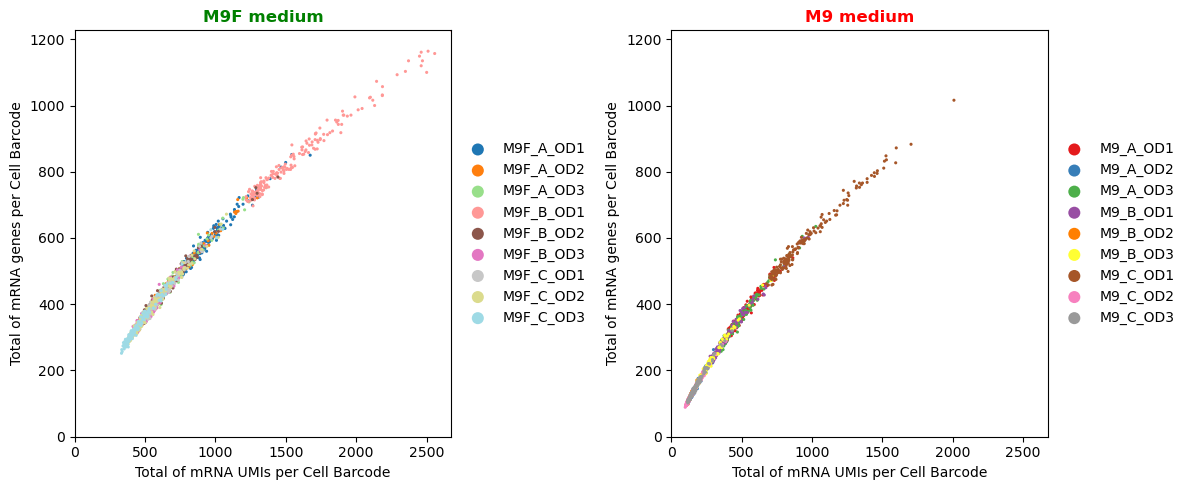

In [36]:
# Create scatter plots comparing M9F vs M9 culture mediums
plot_scatter_comparison_m9f_m9(
    data_gene,
    x_column="total_counts",
    y_column="n_genes_by_counts",
    color_column="OD",
    x_label="Total of mRNA UMIs per Cell Barcode",
    y_label="Total of mRNA genes per Cell Barcode",
    point_size=20,
    figsize=(12, 5),
    title_suffix="",
)

In [37]:
# Sparsity analysis of the data
print("=" * 60)
print("📊 SPARSITY ANALYSIS")
print("=" * 60)

# Calculate sparsity statistics
total_values = data_gene.n_obs * data_gene.n_vars
zero_values = (data_gene.X == 0).sum()
sparsity_percentage = (zero_values / total_values) * 100

print(f"📈 Data dimensions: {data_gene.n_obs:,} cells × {data_gene.n_vars:,} genes")
print(f"🔢 Total number of values: {total_values:,}")
print(f"🕳️  Number of zeros: {zero_values:,}")
print(f"📊 Sparsity percentage: {sparsity_percentage:.1f}%")

# Analysis per cell
genes_per_cell = np.asarray((data_gene.X > 0).sum(axis=1)).squeeze()
print(f"\n🧬 Expressed genes per cell:")
print(f"   - Mean: {genes_per_cell.mean():.0f}")
print(f"   - Median: {np.median(genes_per_cell):.0f}")
print(f"   - Min-Max: {genes_per_cell.min()}-{genes_per_cell.max()}")

# Analysis per gene
cells_per_gene = np.asarray((data_gene.X > 0).sum(axis=0)).squeeze()
print(f"\n🔬 Cells expressing each gene:")
print(f"   - Mean: {cells_per_gene.mean():.0f}")
print(f"   - Median: {np.median(cells_per_gene):.0f}")
print(f"   - Min-Max: {cells_per_gene.min()}-{cells_per_gene.max()}")

📊 SPARSITY ANALYSIS
📈 Data dimensions: 2,988 cells × 5,500 genes
🔢 Total number of values: 16,434,000
🕳️  Number of zeros: 15,326,959
📊 Sparsity percentage: 93.3%

🧬 Expressed genes per cell:
   - Mean: 370
   - Median: 357
   - Min-Max: 89-1227

🔬 Cells expressing each gene:
   - Mean: 201
   - Median: 71
   - Min-Max: 5-2926



💡 WHY ARE THE MATRICES SPARSE?
   🧬 Biological: Each cell only expresses a subset of genes
   🔬 Technical: Dropout, capture efficiency, detection threshold
   💾 Practical: Memory efficiency (storing only non-zeros)
   ⚡ Performance: Faster computations by skipping zeros


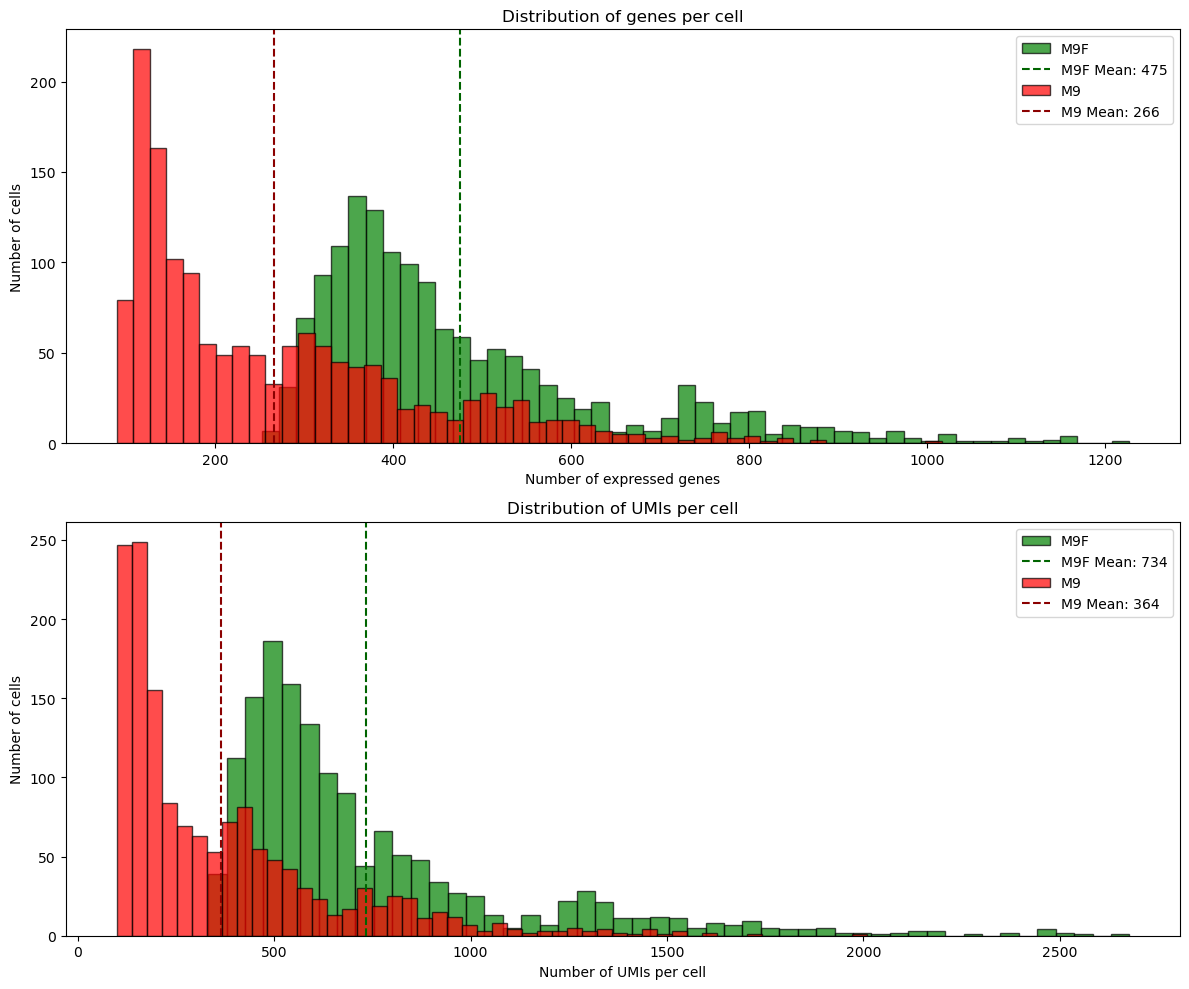

In [38]:
# Distribution visualization - Number of genes per cell
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Histogram of genes per cell - M9F (left, green)
m9f_mask = data_gene.obs["OD"].str.contains("M9F")
genes_per_cell_m9f = genes_per_cell[m9f_mask]
ax1.hist(
    genes_per_cell_m9f,
    bins=50,
    alpha=0.7,
    color="green",
    edgecolor="black",
    label="M9F",
)
ax1.axvline(
    genes_per_cell_m9f.mean(),
    color="darkgreen",
    linestyle="--",
    label=f"M9F Mean: {genes_per_cell_m9f.mean():.0f}",
)

# Histogram of genes per cell - M9 (right, red)
m9_mask = ~data_gene.obs["OD"].str.contains("M9F")
genes_per_cell_m9 = genes_per_cell[m9_mask]
ax1.hist(
    genes_per_cell_m9, bins=50, alpha=0.7, color="red", edgecolor="black", label="M9"
)
ax1.axvline(
    genes_per_cell_m9.mean(),
    color="darkred",
    linestyle="--",
    label=f"M9 Mean: {genes_per_cell_m9.mean():.0f}",
)

ax1.set_xlabel("Number of expressed genes")
ax1.set_ylabel("Number of cells")
ax1.set_title("Distribution of genes per cell")
ax1.legend()

# Distribution visualization - Number of UMIs per cell
total_counts_m9f = data_gene[m9f_mask].obs["total_counts"]
total_counts_m9 = data_gene[m9_mask].obs["total_counts"]

ax2.hist(
    total_counts_m9f, bins=50, alpha=0.7, color="green", edgecolor="black", label="M9F"
)
ax2.axvline(
    total_counts_m9f.mean(),
    color="darkgreen",
    linestyle="--",
    label=f"M9F Mean: {total_counts_m9f.mean():.0f}",
)

ax2.hist(
    total_counts_m9, bins=50, alpha=0.7, color="red", edgecolor="black", label="M9"
)
ax2.axvline(
    total_counts_m9.mean(),
    color="darkred",
    linestyle="--",
    label=f"M9 Mean: {total_counts_m9.mean():.0f}",
)

ax2.set_xlabel("Number of UMIs per cell")
ax2.set_ylabel("Number of cells")
ax2.set_title("Distribution of UMIs per cell")
ax2.legend()

plt.tight_layout()

print(f"\n💡 WHY ARE THE MATRICES SPARSE?")
print(f"   🧬 Biological: Each cell only expresses a subset of genes")
print(f"   🔬 Technical: Dropout, capture efficiency, detection threshold")
print(f"   💾 Practical: Memory efficiency (storing only non-zeros)")
print(f"   ⚡ Performance: Faster computations by skipping zeros")

In [39]:
# Strict gene filtering to avoid problems in SCTransform
import numpy as np

print("=== STRICT GENE FILTERING ===")

# 1. Analyze current data
print(f"1. Initial data:")
print(f"   - Shape: {data_gene.shape}")
print(f"   - Genes: {data_gene.n_vars}")
print(f"   - Cells: {data_gene.n_obs}")

# 2. Calculate gene statistics before filtering
gene_sums_before_filtering = np.array(data_gene.X.sum(axis=0)).flatten()
gene_means_before_filtering = np.array(data_gene.X.mean(axis=0)).flatten()
gene_nonzero_before_filtering = np.array((data_gene.X > 0).sum(axis=0)).flatten()

print(f"\n2. Gene statistics before filtering:")
print(f"   - Sum min: {gene_sums_before_filtering.min()}")
print(f"   - Sum max: {gene_sums_before_filtering.max()}")
print(f"   - Sum mean: {gene_sums_before_filtering.mean():.2f}")
print(f"   - Sum median: {np.median(gene_sums_before_filtering):.2f}")

print(f"\n   - Mean min: {gene_means_before_filtering.min()}")
print(f"   - Mean max: {gene_means_before_filtering.max()}")
print(f"   - Mean mean: {gene_means_before_filtering.mean():.4f}")

print(f"\n   - Non-zero cells min: {gene_nonzero_before_filtering.min()}")
print(f"   - Non-zero cells max: {gene_nonzero_before_filtering.max()}")
print(f"   - Non-zero cells mean: {gene_nonzero_before_filtering.mean():.2f}")

# 2b. Check for problematic values BEFORE filtering
print(f"\n2b. Problematic values check - BEFORE filtering:")
X_before_filtering = (
    data_gene.X.toarray() if hasattr(data_gene.X, "toarray") else data_gene.X
)
print(f"   - NaN values: {np.isnan(X_before_filtering).sum()}")
print(f"   - Infinite values: {np.isinf(X_before_filtering).sum()}")
print(f"   - Negative values: {(X_before_filtering < 0).sum()}")

# 3. Define strict filtering criteria
min_total_counts = 20  # At least 20 total counts per gene
min_cells_expressed = 5  # Expressed in at least 5 cells
min_mean_expression = 0.1  # Mean expression of at least 0.1

print(f"\n3. Filtering criteria:")
print(f"   - Minimum total counts: {min_total_counts}")
print(f"   - Minimum cells expressed: {min_cells_expressed}")
print(f"   - Minimum mean expression: {min_mean_expression}")

# 4. Apply filtering
mask_total_counts = gene_sums_before_filtering >= min_total_counts
mask_cells_expressed = gene_nonzero_before_filtering >= min_cells_expressed
mask_mean_expression = gene_means_before_filtering >= min_mean_expression

# Combine all criteria
mask_combined_strict_filtering = (
    mask_total_counts & mask_cells_expressed & mask_mean_expression
)

print(f"\n4. Filtering results:")
print(f"   - Genes passing total counts criterion: {mask_total_counts.sum()}")
print(f"   - Genes passing cells expressed criterion: {mask_cells_expressed.sum()}")
print(f"   - Genes passing mean expression criterion: {mask_mean_expression.sum()}")
print(f"   - Genes passing ALL criteria: {mask_combined_strict_filtering.sum()}")

# 5. Create filtered dataset
data_gene_after_strict_filtering = data_gene[:, mask_combined_strict_filtering].copy()

print(f"\n5. Filtered dataset:")
print(f"   - Shape: {data_gene_after_strict_filtering.shape}")
print(f"   - Genes retained: {data_gene_after_strict_filtering.n_vars}")
print(
    f"   - Percentage of genes retained: {data_gene_after_strict_filtering.n_vars/data_gene.n_vars*100:.1f}%"
)

# 6. Verify filtered data
gene_sums_after_strict_filtering = np.array(
    data_gene_after_strict_filtering.X.sum(axis=0)
).flatten()
gene_means_after_strict_filtering = np.array(
    data_gene_after_strict_filtering.X.mean(axis=0)
).flatten()
gene_nonzero_after_strict_filtering = np.array(
    (data_gene_after_strict_filtering.X > 0).sum(axis=0)
).flatten()

print(f"\n6. Statistics after filtering:")
print(f"   - Sum min: {gene_sums_after_strict_filtering.min()}")
print(f"   - Sum mean: {gene_sums_after_strict_filtering.mean():.2f}")
print(f"   - Mean min: {gene_means_after_strict_filtering.min()}")
print(f"   - Mean mean: {gene_means_after_strict_filtering.mean():.4f}")
print(f"   - Non-zero cells min: {gene_nonzero_after_strict_filtering.min()}")
print(f"   - Non-zero cells mean: {gene_nonzero_after_strict_filtering.mean():.2f}")

# 7. Check for problematic values AFTER filtering
print(f"\n7. Problematic values check - AFTER filtering:")
X_after_strict_filtering = (
    data_gene_after_strict_filtering.X.toarray()
    if hasattr(data_gene_after_strict_filtering.X, "toarray")
    else data_gene_after_strict_filtering.X
)
print(f"   - NaN values: {np.isnan(X_after_strict_filtering).sum()}")
print(f"   - Infinite values: {np.isinf(X_after_strict_filtering).sum()}")
print(f"   - Negative values: {(X_after_strict_filtering < 0).sum()}")

print("=== FILTERING COMPLETED ===")

data_gene = data_gene_after_strict_filtering.copy()

=== STRICT GENE FILTERING ===
1. Initial data:
   - Shape: (2988, 5500)
   - Genes: 5500
   - Cells: 2988

2. Gene statistics before filtering:
   - Sum min: 5
   - Sum max: 26121
   - Sum mean: 298.25
   - Sum median: 72.00

   - Mean min: 0.0016733601070950468
   - Mean max: 8.741967871485944
   - Mean mean: 0.0998

   - Non-zero cells min: 5
   - Non-zero cells max: 2926
   - Non-zero cells mean: 201.28

2b. Problematic values check - BEFORE filtering:
   - NaN values: 0
   - Infinite values: 0
   - Negative values: 0

3. Filtering criteria:
   - Minimum total counts: 20
   - Minimum cells expressed: 5
   - Minimum mean expression: 0.1

4. Filtering results:
   - Genes passing total counts criterion: 4589
   - Genes passing cells expressed criterion: 5500
   - Genes passing mean expression criterion: 1013
   - Genes passing ALL criteria: 1013

5. Filtered dataset:
   - Shape: (2988, 1013)
   - Genes retained: 1013
   - Percentage of genes retained: 18.4%

6. Statistics after filteri

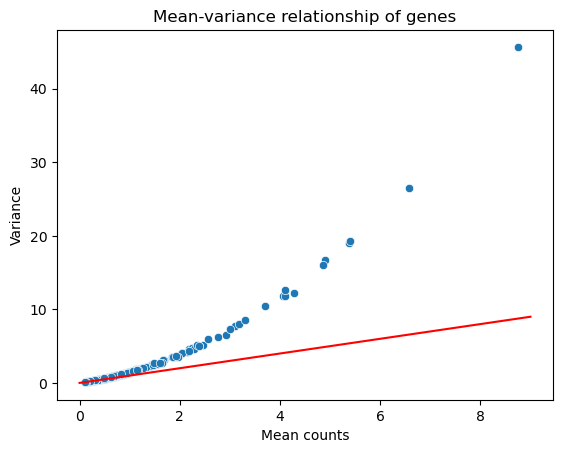

Data is overdispersed - use Negative Binomial count splitting


In [40]:
# Save raw counts into a layer of the anndata
data_gene.layers["counts"] = data_gene.X.copy()

data_gene.var["var_counts"] = np.asarray(
    np.var(data_gene.X.toarray(), axis=0)
).squeeze()
data_gene.var["mean_counts"] = np.asarray(
    np.mean(data_gene.X.toarray(), axis=0)
).squeeze()
sns.scatterplot(data=data_gene.var, x="mean_counts", y="var_counts")
plt.plot(
    [0, np.ceil(np.max(data_gene.var["mean_counts"]))],
    [0, np.ceil(np.max(data_gene.var["mean_counts"]))],
    color="red",
)
plt.title("Mean-variance relationship of genes")
plt.xlabel("Mean counts")
plt.ylabel("Variance")
plt.show()

# See if a linear or quadratic relationship fits better
mv_corr_lin = np.corrcoef(data_gene.var["mean_counts"], data_gene.var["var_counts"])[
    0, 1
]
mv_corr_sq = np.corrcoef(
    data_gene.var["mean_counts"] ** 2, data_gene.var["var_counts"]
)[0, 1]

if mv_corr_sq > mv_corr_lin:
    is_overdispersed = True
else:
    is_overdispersed = False

if is_overdispersed:
    print("Data is overdispersed - use Negative Binomial count splitting")
else:
    print("Data is not overdispersed - use Poisson count splitting")

In [41]:
## Estimate negative binomial parameters for each gene

# We use scTransform to estimate the dispersion parameter for each gene, which we will use for variance stabilization

importlib.reload(nb)
nb.estimate_overdisp_nb(data_gene, layer="counts", flavor="sctransform", seed=5678)

In [ ]:
## Count splitting for variance stabilization

# Determine distribution for count splitting
if is_overdispersed:
    data_dist = "NB"
else:
    data_dist = "Poi"

print(f"Using {data_dist} distribution for count splitting")

# Ensure data is in dense format for count splitting
if hasattr(data_gene.X, "toarray"):
    print("Converting sparse matrix to dense for count splitting...")
    data_gene.X = data_gene.X.toarray()

# Also convert the counts layer to dense
if hasattr(data_gene.layers["counts"], "toarray"):
    data_gene.layers["counts"] = data_gene.layers["counts"].toarray()

print(f"Data type of X: {type(data_gene.X)}")
print(f"Data type of counts layer: {type(data_gene.layers['counts'])}")

# Apply count splitting
data_train, data_test = cs.countsplit_adata(
    data_gene,
    data_dist=data_dist,
    beta_key="nb_overdisp_cutoff",
    layer="counts",
    min_genes=1,
    max_counts=1e9,
    seed=1234,
)
print(data_train)
print(data_test)

In [ ]:
## Count splitting for train/test data

# Determine distribution type for count splitting
if is_overdispersed:
    data_dist = "NB"
else:
    data_dist = "Poi"

print(f"Using {data_dist} distribution for count splitting")

# Convert sparse matrix to dense array for count splitting
print("Converting sparse matrix to dense array...")
print(f"Original matrix type: {type(data_gene.X)}")

# Make sure we have a dense array in the counts layer
if hasattr(data_gene.layers["counts"], "toarray"):
    data_gene.layers["counts"] = data_gene.layers["counts"].toarray()

print(f"Counts layer type after conversion: {type(data_gene.layers['counts'])}")

# Perform count splitting
print("Performing count splitting...")
data_train, data_test = cs.countsplit_adata(
    data_gene,
    data_dist=data_dist,
    beta_key="nb_overdisp_cutoff",
    layer="counts",
    min_genes=1,
    max_counts=1e9,
    seed=1234,
)

print(f"Train data shape: {data_train.shape}")
print(f"Test data shape: {data_test.shape}")
print("Count splitting completed successfully!")

In [42]:
table = data_gene.var

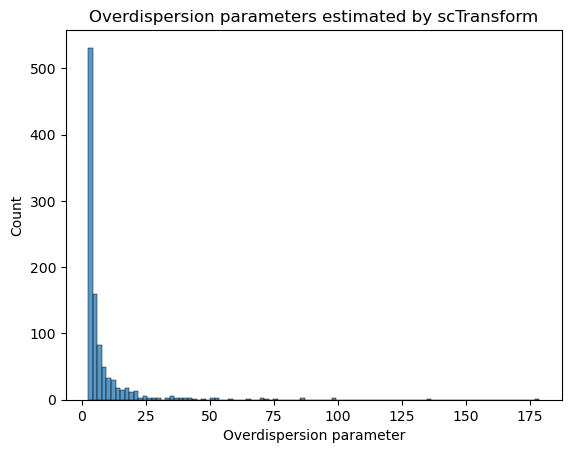

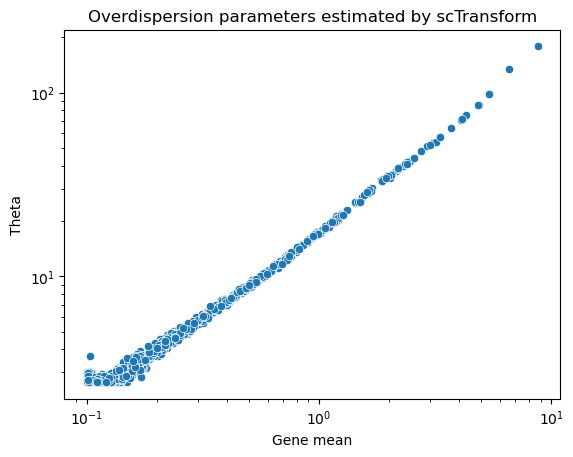

In [43]:
# Quick diagnostic plot - maybe we can spot some outlier genes here that prompt further investigation
sns.histplot(data=data_gene.var, x="nb_overdisp_cutoff", bins=100)
plt.title("Overdispersion parameters estimated by scTransform")
plt.xlabel("Overdispersion parameter")
plt.show()

g = sns.scatterplot(data=data_gene.var, y="nb_overdisp_cutoff", x="mean_counts")
g.set(xscale="log", yscale="log")
plt.title("Overdispersion parameters estimated by scTransform")
plt.xlabel("Gene mean")
plt.ylabel("Theta")
plt.show()

In [44]:
data_gene.X = data_gene.layers["counts"].copy()

# %%

## Normalization, VST, scaling and PCA

Normalize, scale and perform PCA on the data

In [ ]:
sc.pp.normalize_total(data_gene, target_sum=None, layer=None)
if is_overdispersed:
    data_gene.X = sps.csr_matrix(
        np.log(
            data_gene.X.toarray() + np.array(data_gene.var["nb_overdisp_cutoff"] / 4)
        )
    )
else:
    # data_gene.X = sps.csr_matrix(np.sqrt(data_gene.X.toarray()))
    data_gene.X = sps.csr_matrix(
        np.log(
            data_gene.X.toarray() + np.array(data_gene.var["nb_overdisp_cutoff"] / 4)
        )
    )

data_gene.layers["vst_counts"] = data_gene.X.copy()
sc.pp.scale(data_gene, max_value=10, zero_center=True)
sc.tl.pca(data_gene, svd_solver="arpack")

Histograms of cell sequencing depths before normalization, after VST and after scaling. The data should be more centered than before

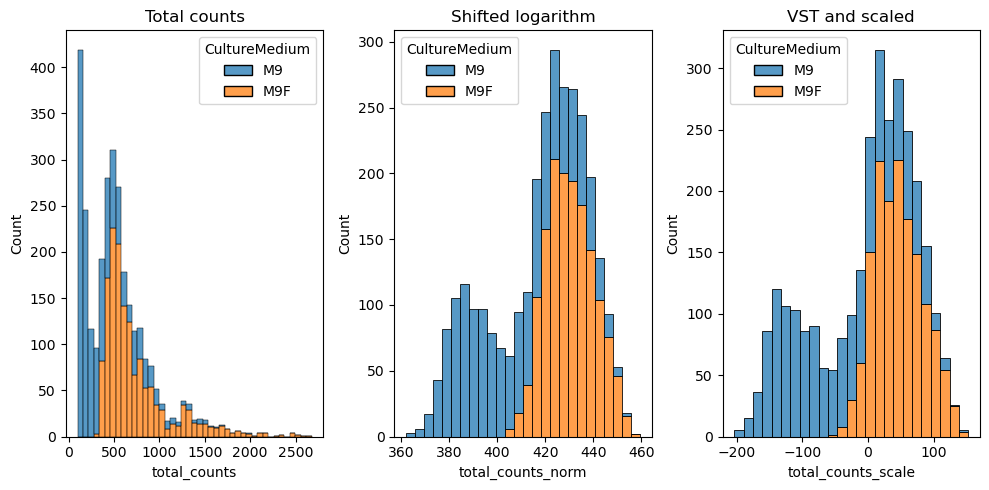

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
p1 = sns.histplot(
    data=data_gene.obs,
    x="total_counts",
    hue="CultureMedium",
    kde=False,
    ax=axes[0],
    multiple="stack",
)
axes[0].set_title("Total counts")
data_gene.obs["total_counts_norm"] = data_gene.layers["vst_counts"].sum(1)
p2 = sns.histplot(
    data=data_gene.obs,
    x="total_counts_norm",
    hue="CultureMedium",
    kde=False,
    ax=axes[1],
    multiple="stack",
)
axes[1].set_title("Shifted logarithm")
data_gene.obs["total_counts_scale"] = data_gene.X.sum(1)
p2 = sns.histplot(
    data=data_gene.obs,
    x="total_counts_scale",
    hue="CultureMedium",
    kde=False,
    ax=axes[2],
    multiple="stack",
)
axes[2].set_title("VST and scaled")
plt.tight_layout()
plt.show()

## Count-splitting into train and test data

This step creates a train and test dataset, which we use to determine the latent dimensionality and clustering resolution further down the line

In [ ]:
## Count splitting for train/test data

# Determine distribution type for count splitting
if is_overdispersed:
    data_dist = "NB"
else:
    data_dist = "Poi"

print(f"Using {data_dist} distribution for count splitting")

# Convert sparse matrix to dense array for count splitting
print("Converting sparse matrix to dense array...")
print(f"Original matrix type: {type(data_gene.X)}")

# Make sure we have a dense array in the counts layer
if hasattr(data_gene.layers["counts"], "toarray"):
    data_gene.layers["counts"] = data_gene.layers["counts"].toarray()

print(f"Counts layer type after conversion: {type(data_gene.layers['counts'])}")

# Perform count splitting
print("Performing count splitting...")
data_train, data_test = cs.countsplit_adata(
    data_gene,
    data_dist=data_dist,
    beta_key="nb_overdisp_cutoff",
    layer="counts",
    min_genes=1,
    max_counts=1e9,
    seed=1234,
)

print(f"Train data shape: {data_train.shape}")
print(f"Test data shape: {data_test.shape}")
print("Count splitting completed successfully!")

Using NB distribution for count splitting
Converting sparse matrix to dense array...
Original matrix type: <class 'numpy.ndarray'>
Counts layer type after conversion: <class 'numpy.ndarray'>
Performing count splitting...
Train data shape: (2988, 1013)
Test data shape: (2988, 1013)
Count splitting completed successfully!


Process the data in the same way as the fulld dataset (Normalize, scale, PCA)

In [49]:
sc.pp.normalize_total(data_train, target_sum=None, layer=None)
if is_overdispersed:
    data_train.X = sps.csr_matrix(
        np.log(
            data_train.X.toarray() + np.array(data_train.var["nb_overdisp_cutoff"] / 4)
        )
    )
else:
    data_train.X = sps.csr_matrix(np.sqrt(data_train.X.toarray()))
data_train.layers["vst_counts"] = data_train.X.copy()
sc.pp.scale(data_train, max_value=10, zero_center=True)
sc.tl.pca(data_train, svd_solver="arpack")


sc.pp.normalize_total(data_test, target_sum=None, layer=None)
if is_overdispersed:
    data_test.X = sps.csr_matrix(
        np.log(
            data_test.X.toarray() + np.array(data_train.var["nb_overdisp_cutoff"] / 4)
        )
    )
else:
    data_test.X = sps.csr_matrix(np.sqrt(data_test.X.toarray()))
data_test.layers["vst_counts"] = data_test.X.copy()
sc.pp.scale(data_test, max_value=10, zero_center=True)
sc.tl.pca(data_test, svd_solver="arpack")

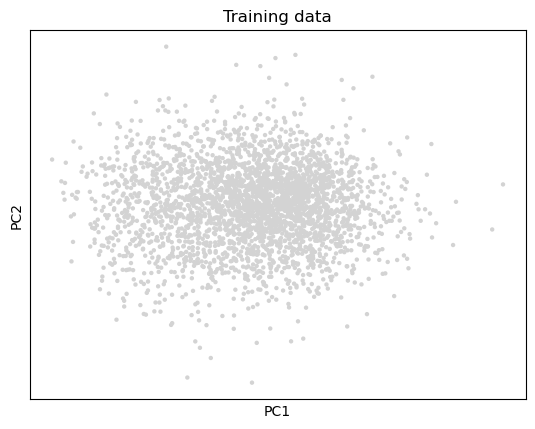

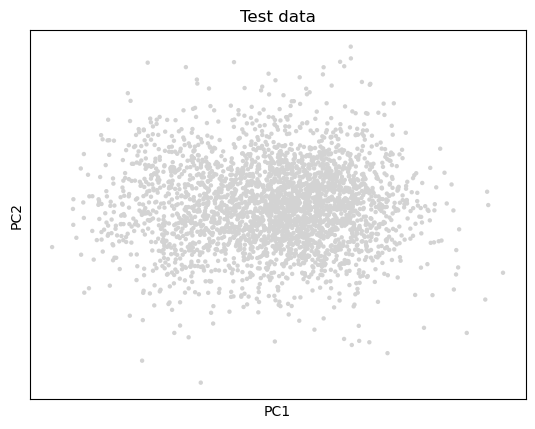

In [51]:
sc.pl.pca(data_train, title="Training data")
plt.show()

sc.pl.pca(data_test, title="Test data")
plt.show()

### Principal component selection

Select the optimal latent dimensionality k - the curve below should have a nice minimum

In [52]:
k_errors, k_opt = cs.select_n_pcs_countsplit(data_train, data_test)
print(f"Optimal number of PCs:{k_opt}")
data_gene.uns["BacSC_params"] = {"k_opt": k_opt}

Optimal number of PCs:1


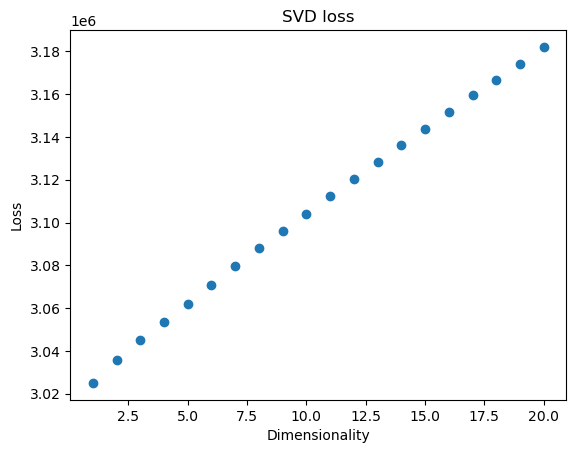

In [54]:
plt.scatter(np.arange(20) + 1, k_errors)
plt.title("SVD loss")
plt.xlabel("Dimensionality")
plt.ylabel("Loss")
plt.show()

Plot the PCA of the full dataset

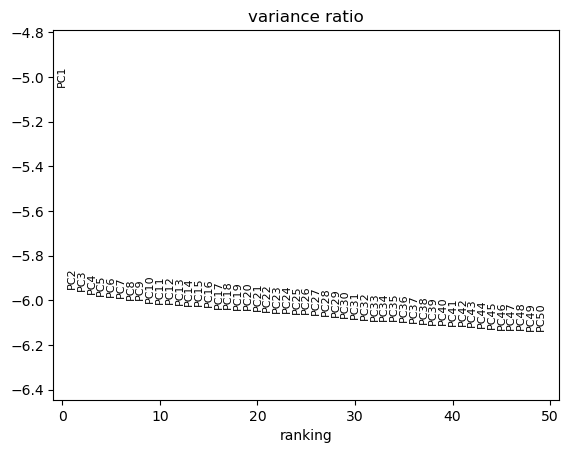

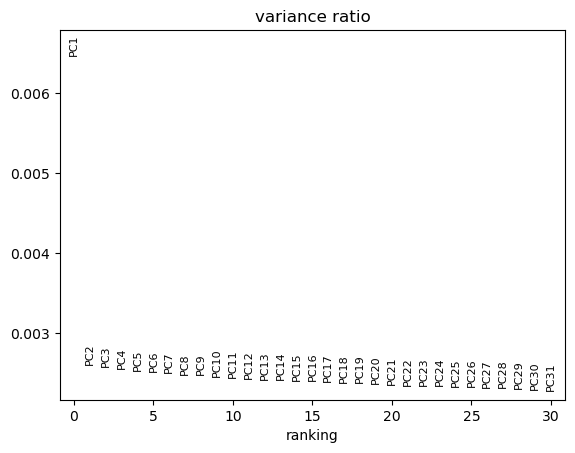

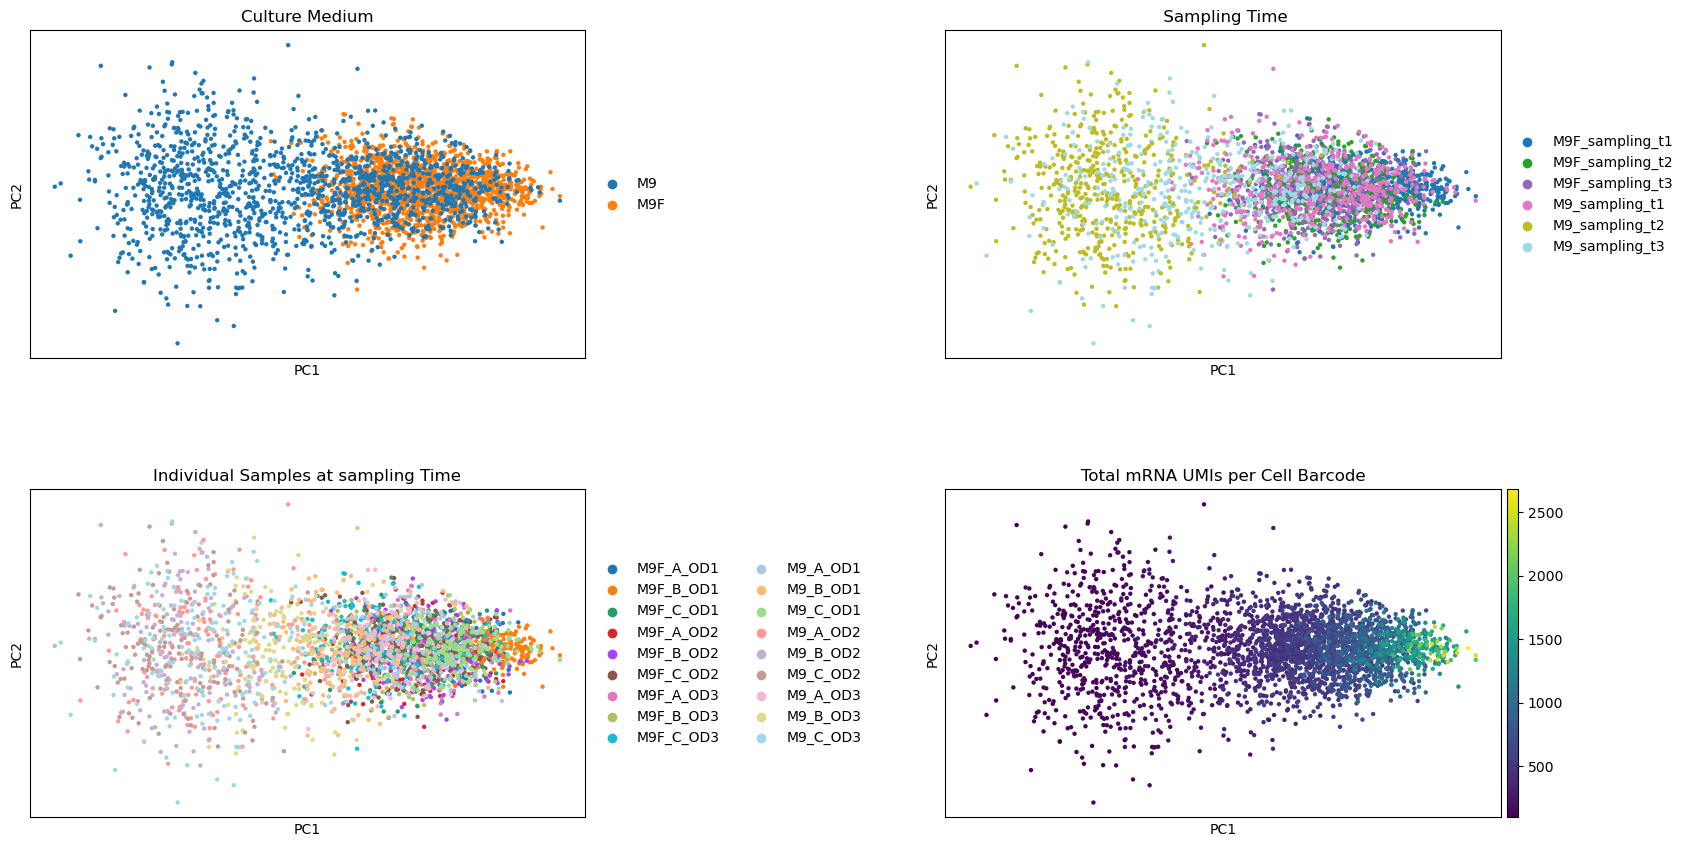

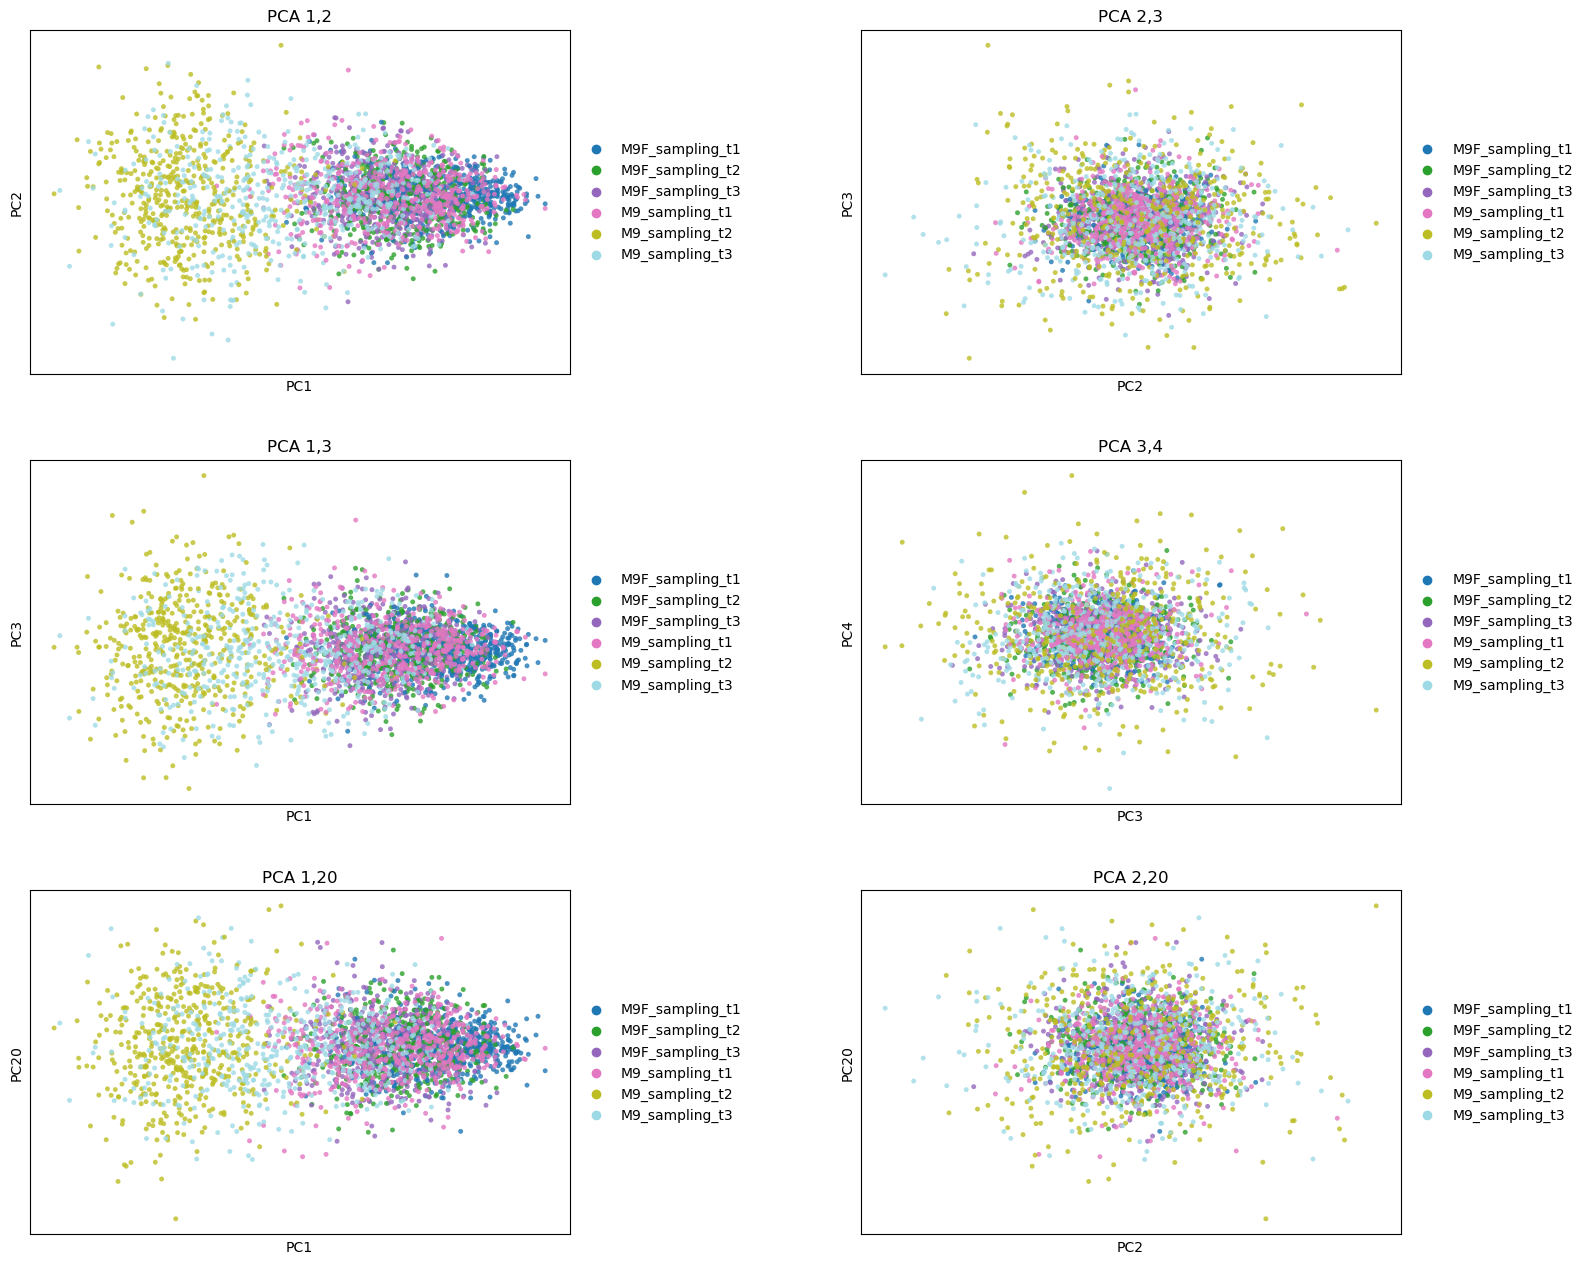

In [61]:
sc.pl.pca_variance_ratio(data_gene, log=True, n_pcs=50)


# Création de la colonne de regroupement 'group' selon la logique demandée
def assign_group(row):
    prefix = row["CultureMedium"]  # M9 ou M9F
    odt = row["ODt"]
    if odt == "OD1":
        suffix = "sampling_t1"
    elif odt == "OD2":
        suffix = "sampling_t2"
    elif odt == "OD3":
        suffix = "sampling_t3"
    else:
        suffix = "sampling_unknown"
    return f"{prefix}_{suffix}"


data_gene.obs["group"] = data_gene.obs.apply(assign_group, axis=1)

# ordered OD samples
ordered_samples = [
    "M9F_A_OD1",
    "M9F_B_OD1",
    "M9F_C_OD1",
    "M9F_A_OD2",
    "M9F_B_OD2",
    "M9F_C_OD2",
    "M9F_A_OD3",
    "M9F_B_OD3",
    "M9F_C_OD3",
    "M9_A_OD1",
    "M9_B_OD1",
    "M9_C_OD1",
    "M9_A_OD2",
    "M9_B_OD2",
    "M9_C_OD2",
    "M9_A_OD3",
    "M9_B_OD3",
    "M9_C_OD3",
]

# Order the OD categories in the AnnData object
data_gene.obs["OD"] = pd.Categorical(
    data_gene.obs["OD"], categories=ordered_samples, ordered=True
)
sc.pl.pca_variance_ratio(data_gene, log=False)
sc.pl.pca(
    data_gene,
    ncols=2,
    color=["CultureMedium", "group", "OD", "total_counts"],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        " Sampling Time",
        "Individual Samples at sampling Time",
        "Total mRNA UMIs per Cell Barcode",
    ],
    wspace=0.5,  # Increase horizontal spacing between plots
    hspace=0.4,  # Increase vertical spacing between plots
)

# Plot different PCA component combinations
sc.pl.pca(
    data_gene,
    components=["1,2", "2,3", "1,3", "3,4", "1,20", "2,20"],
    color=["group"],
    ncols=2,
    title=["PCA 1,2", "PCA 2,3", "PCA 1,3", "PCA 3,4", "PCA 1,20", "PCA 2,20"],
    palette="tab20",
    alpha=0.8,
    size=50,
    wspace=0.4,
)

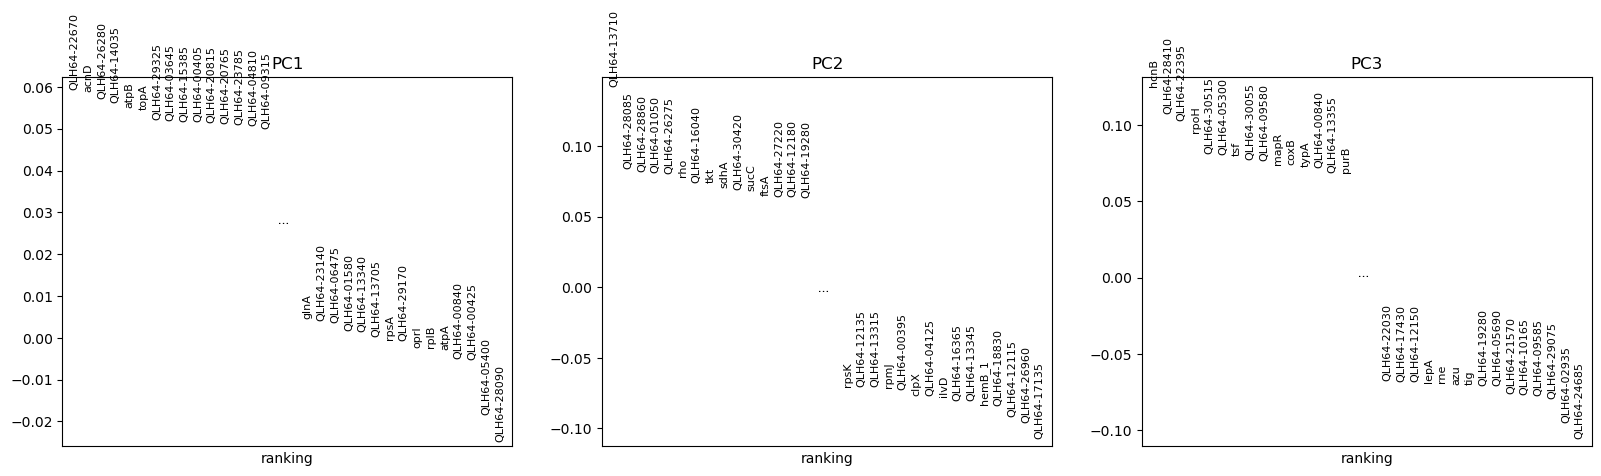

In [59]:
sc.pl.pca_loadings(data_gene, components=[1, 2, 3])

In [ ]:
# Étape 1 : Obtenir les 20 gènes les plus positifs et négatifs des PCA 1,2 et les trier par importance
top_pos_pc1 = data_gene.varm["PCs"][:, 0].argsort()[-20:][
    ::-1
]  # 20 plus positifs PC1, triés par ordre décroissant
top_neg_pc1 = data_gene.varm["PCs"][:, 0].argsort()[
    :20
]  # 20 plus négatifs PC1, déjà triés par ordre croissant
top_pos_pc2 = data_gene.varm["PCs"][:, 1].argsort()[-20:][
    ::-1
]  # 20 plus positifs PC2, triés par ordre décroissant
top_neg_pc2 = data_gene.varm["PCs"][:, 1].argsort()[
    :20
]  # 20 plus négatifs PC2, déjà triés par ordre croissant

# Create DataFrames for each PC component with loading values
import pandas as pd


def create_gene_df(indices, pc_num, direction):
    loadings = data_gene.varm["PCs"][indices, pc_num - 1]  # Get actual loading values
    df = pd.DataFrame(
        {
            "final_gene_name": data_gene.var["final_gene_name"][indices],
            "Name": data_gene.var["Name"][indices],
            "loading_value": abs(loadings),  # Absolute loading value for sorting
            "n_cells_by_counts": data_gene.var["n_cells_by_counts"][indices],
            "mean_counts": data_gene.var["mean_counts"][indices],
            "total_counts": data_gene.var["total_counts"][indices],
            "PC": [f"PC{pc_num}"] * len(indices),
            "Direction": [direction] * len(indices),
        }
    )
    return df.sort_values(
        "loading_value", ascending=False
    )  # Sort by absolute loading value


# Create sorted DataFrames for each component
pc1_pos_df = create_gene_df(top_pos_pc1, 1, "positive")
pc1_neg_df = create_gene_df(top_neg_pc1, 1, "negative")
pc2_pos_df = create_gene_df(top_pos_pc2, 2, "positive")
pc2_neg_df = create_gene_df(top_neg_pc2, 2, "negative")

# Combine all DataFrames
all_genes_df = pd.concat([pc1_pos_df, pc1_neg_df, pc2_pos_df, pc2_neg_df])

# Sort the full table by PC and loading value
sorted_genes_df = all_genes_df.sort_values(
    ["PC", "loading_value"], ascending=[True, False]
)

# Print the sorted table
print(sorted_genes_df)

            final_gene_name  \
gene_name                     
QLH64-22670     QLH64-22670   
acnD                   acnD   
QLH64-26280     QLH64-26280   
QLH64-14035     QLH64-14035   
atpB                   atpB   
...                     ...   
QLH64-04740     QLH64-04740   
QLH64-25260     QLH64-25260   
QLH64-22540     QLH64-22540   
QLH64-18400     QLH64-18400   
hslU                   hslU   

                                                          Name  loading_value  \
gene_name                                                                       
QLH64-22670                                           catalase       0.059437   
acnD         Fe/S-dependent 2-methylisocitrate dehydratase ...       0.058922   
QLH64-26280                            type I secretion target       0.057076   
QLH64-14035                           PAS domain S-box protein       0.056328   
atpB                               F0F1 ATP synthase subunit A       0.055094   
...                          

In [71]:
# Use these parameters if you don't want to run scDEED
n_neighbors_opt = 20
min_dist_opt = 0.3

In [67]:
sc.pp.neighbors(data_gene, n_neighbors=10, n_pcs=5)
sc.tl.umap(
    data_gene,
    neighbors_key="neighbors",
    min_dist=min_dist_opt,
    spread=1,
    random_state=3456,
)

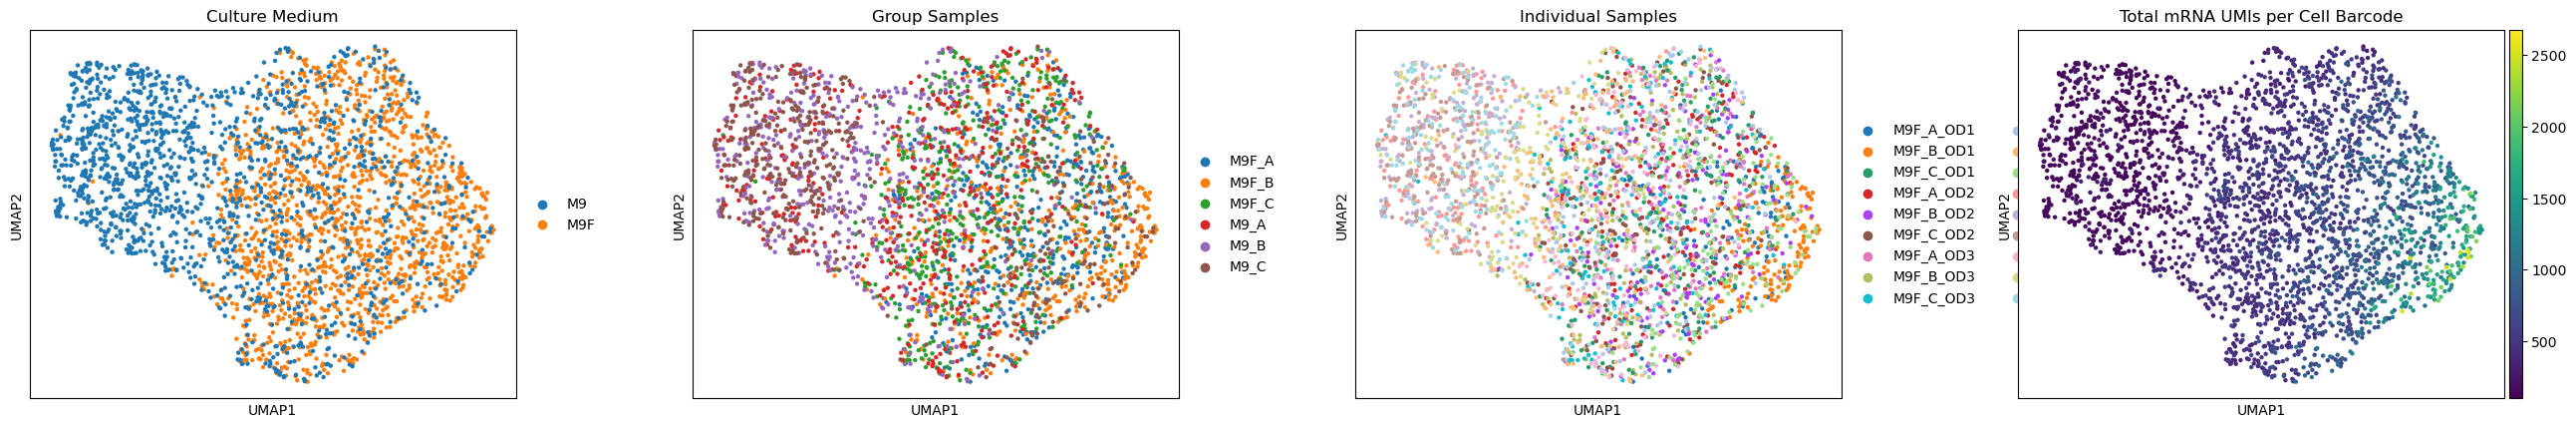

In [68]:
sc.pl.umap(
    data_gene,
    color=["CultureMedium", "RepBio", "OD", "total_counts"],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        "Group Samples",
        "Individual Samples",
        "Total mRNA UMIs per Cell Barcode",
    ],
    wspace=0.24,  # Increase space between plots horizontally
    hspace=0.3,  # Increase space between plots vertically
)
plt.show()

  Using cached leidenalg-0.10.2-cp38-abi3-macosx_11_0_arm64.whl.metadata (10 kB)
Using cached leidenalg-0.10.2-cp38-abi3-macosx_11_0_arm64.whl (1.4 MB)


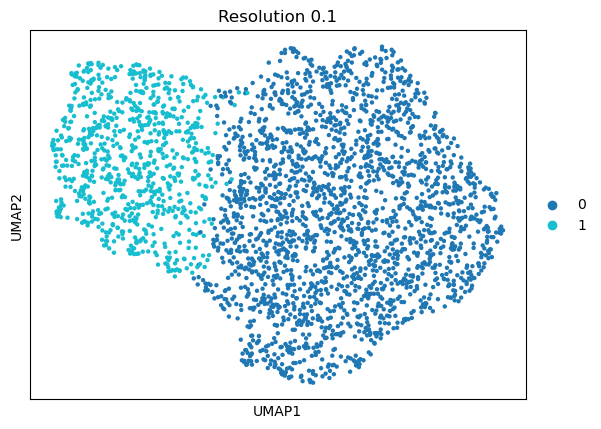

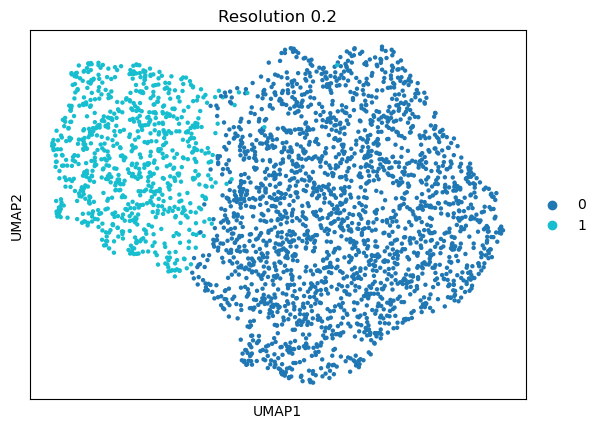

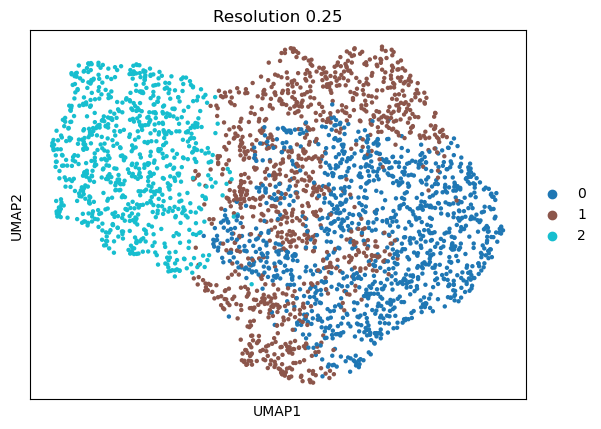

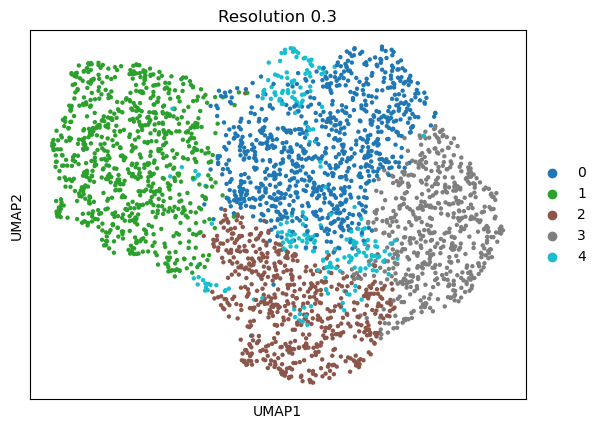

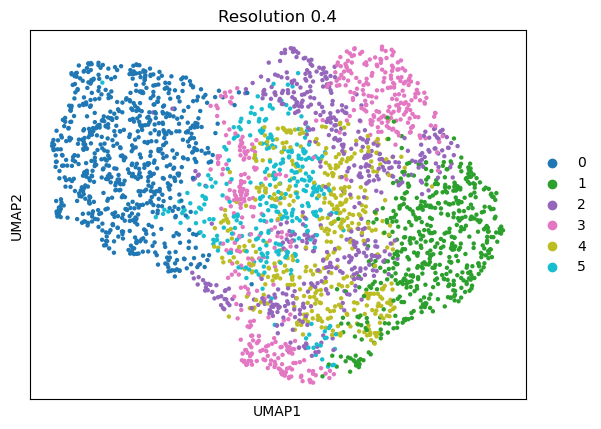

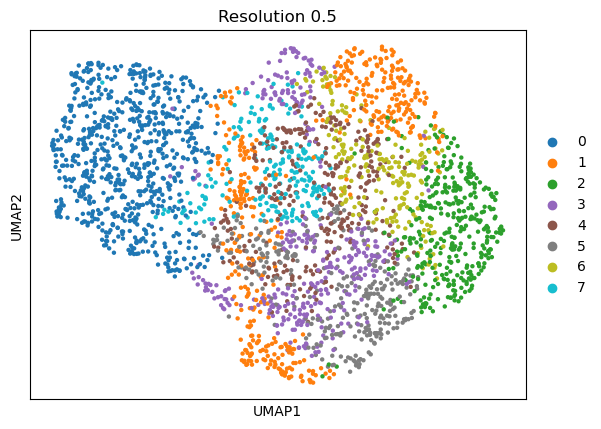

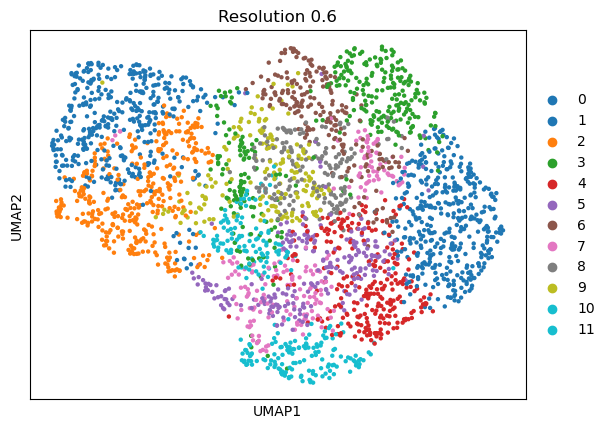

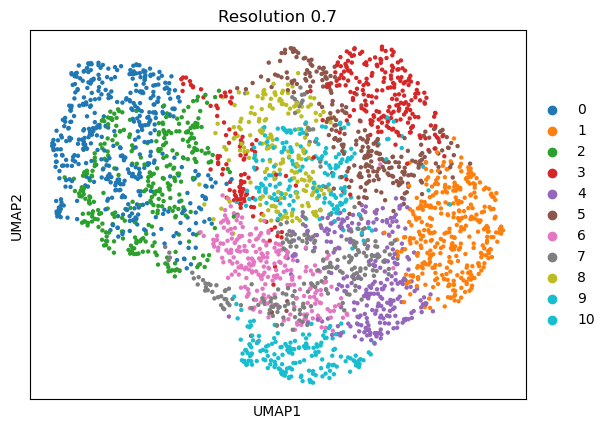

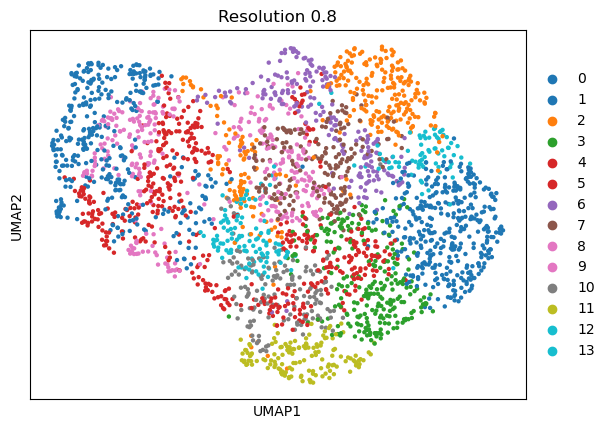

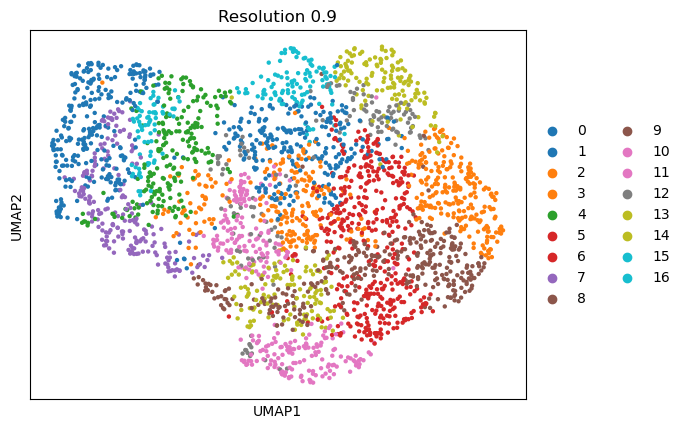

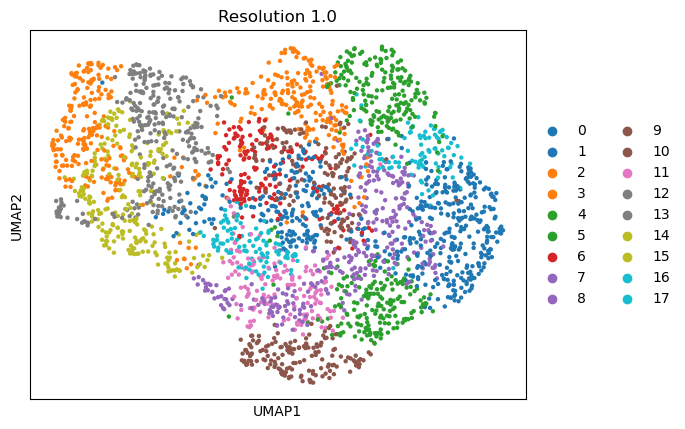

In [74]:
!pip install igraph
!pip install leidenalg
# create differente resolution for leiden clustering with for loop
for resolution in [0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    sc.tl.leiden(
        data_gene,
        resolution=resolution,
        key_added=f"leiden_opt_{resolution}",
        random_state=1234,
    )

# plot the differente resolution for leiden clustering with for loop
for resolution in [0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    sc.pl.umap(
        data_gene,
        color=f"leiden_opt_{resolution}",
        palette="tab10",
        title=f"Resolution {resolution}",
    )
    plt.show()

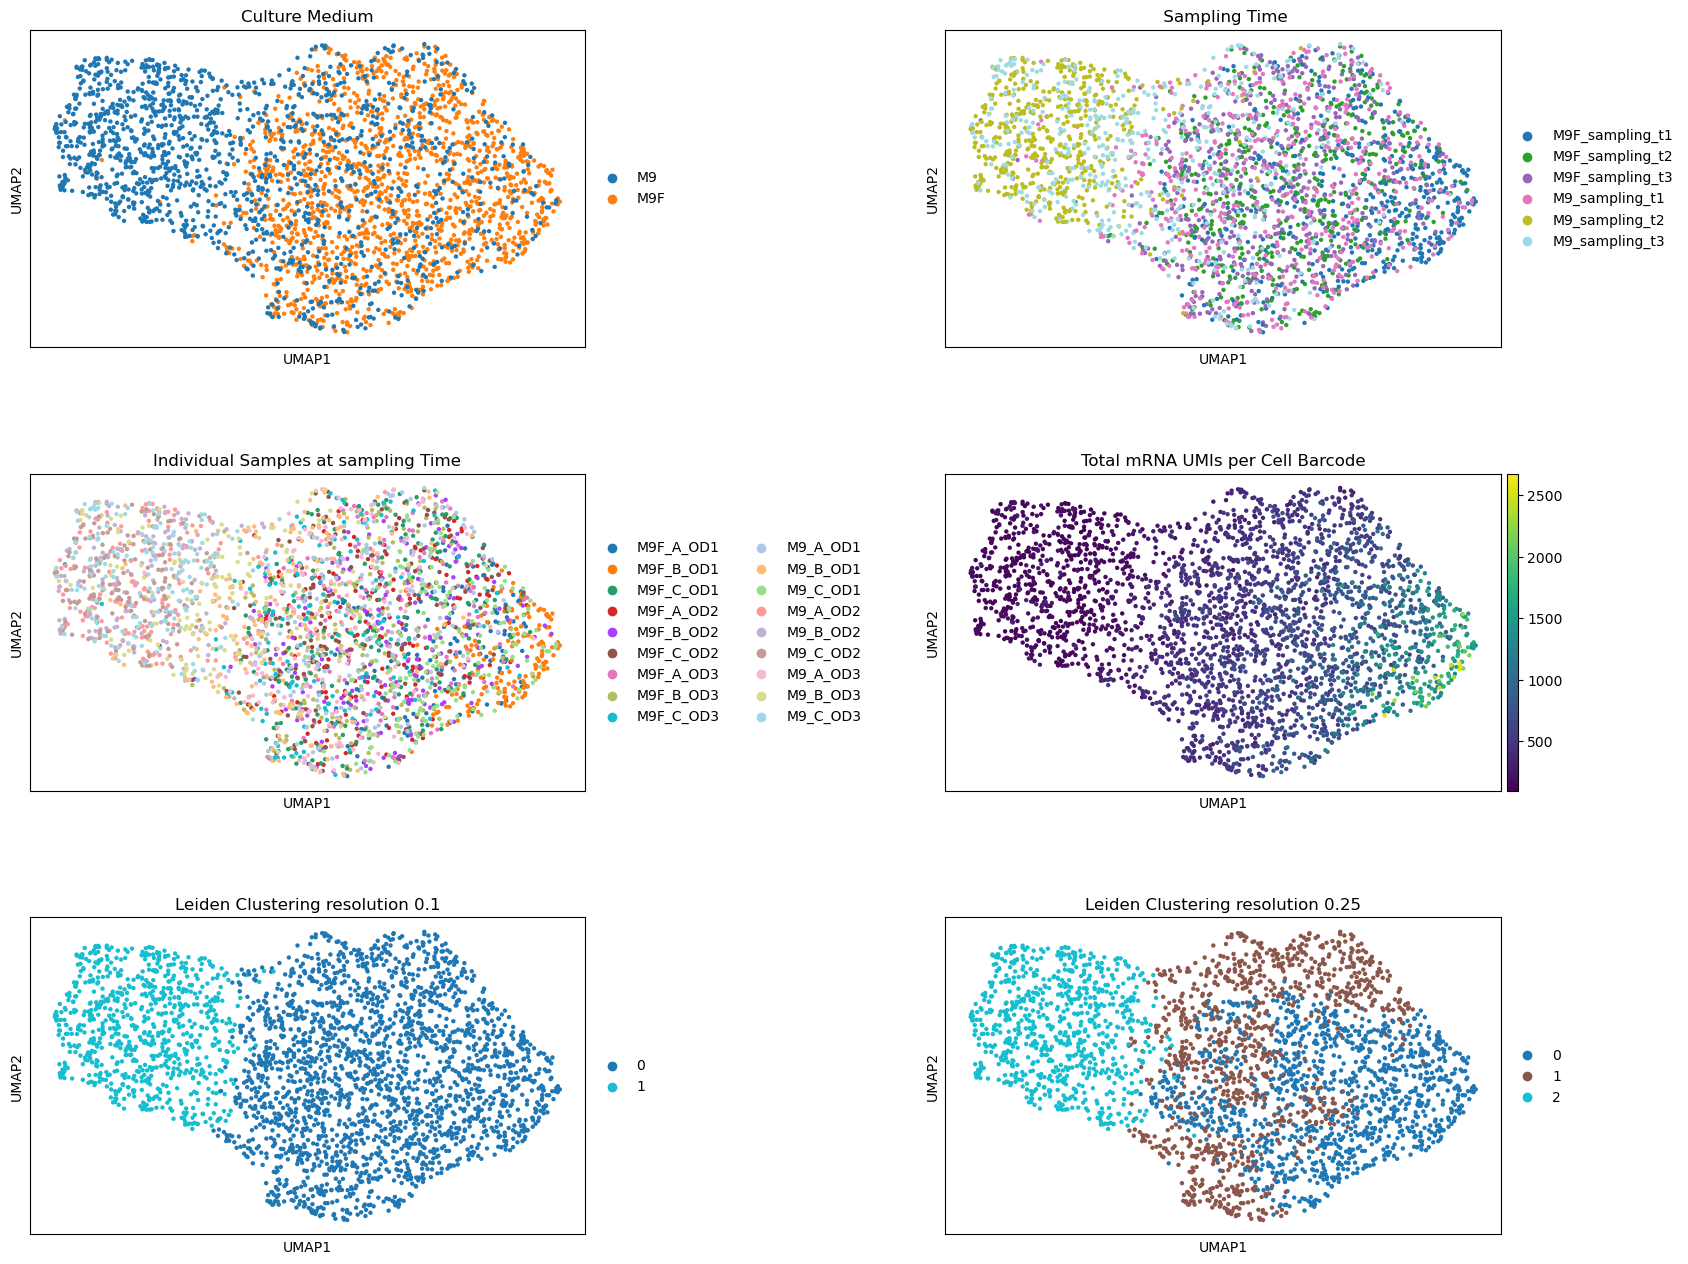

In [76]:
sc.pl.umap(
    data_gene,
    ncols=2,
    color=[
        "CultureMedium",
        "group",
        "OD",
        "total_counts",
        "leiden_opt_0.1",
        "leiden_opt_0.25",
    ],
    alpha=1,
    cmap="viridis",
    title=[
        "Culture Medium",
        " Sampling Time",
        "Individual Samples at sampling Time",
        "Total mRNA UMIs per Cell Barcode",
        "Leiden Clustering resolution 0.1",
        "Leiden Clustering resolution 0.25",
    ],
    wspace=0.5,  # Increase horizontal spacing between plots
    hspace=0.4,  # Increase vertical spacing between plots
)

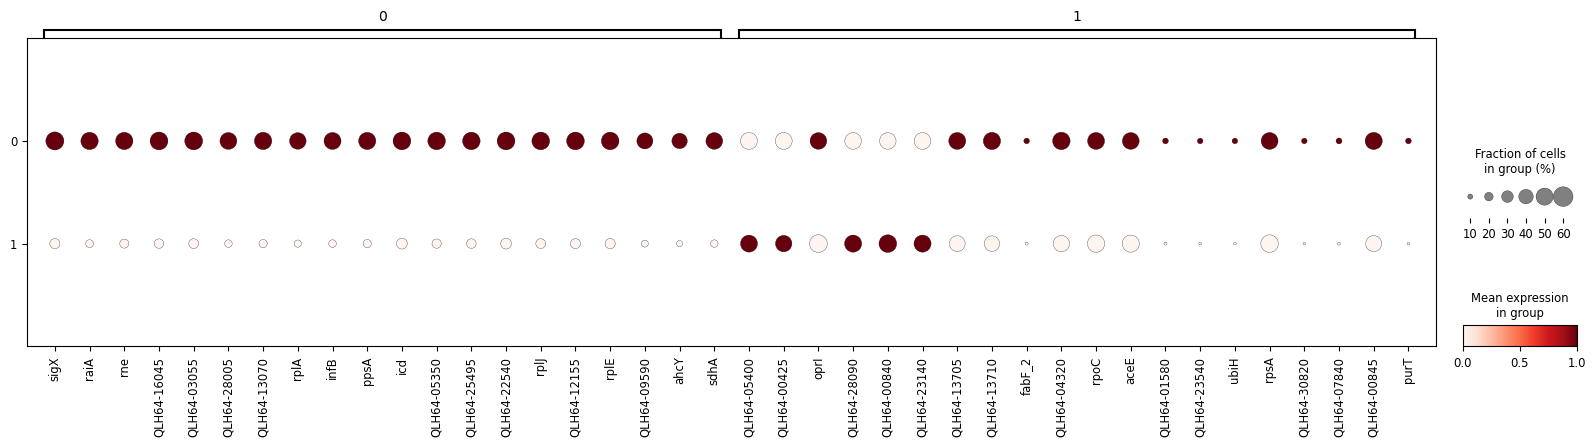

In [79]:
import scanpy as sc

# Effectuer le test de gènes différentiellement exprimés entre les clusters
sc.tl.rank_genes_groups(data_gene, groupby="leiden_opt_0.1", method="wilcoxon")

# Afficher le dotplot des top gènes
sc.pl.rank_genes_groups_dotplot(
    data_gene,
    groupby="leiden_opt_0.1",
    n_genes=20,  # nombre de gènes par cluster
    standard_scale="var",  # ou None pour valeurs brutes
    show=True,
    figsize=(20, 4),
)